# Parte III — Inversão de comprimento variável e generalização de comprimento

**DAS410116 — Inteligência Artificial Generativa · UFSC · 2026/2**
**Professor:** Eric A. Antonelo
**Aluno:** Leonardo Coli
**Fontes e uso de IA:** Claude.

As posições one-hot da Parte II são trocadas por features de dimensão fixa. O treino usa $L\in\{4,5,6,7,8\}$, e o teste cobre interpolação e extrapolação.

Não há dimensão de batch, e a matriz de atenção não é alvo de treino.

## 0. Configuração

In [1]:
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(7)
torch.set_printoptions(precision=3, sci_mode=False)

## 1. Features posicionais de dimensão fixa — 0,40 ponto

Para $p_i=-1+2i/(L-1)$:

$$\phi(p_i)=[1,\ p_i,\ p_i^2].$$

In [2]:
def positional_features(L, device=None):
    # 1.1: p com shape (L, 1), igualmente espaçado em [-1, 1]: p_i = -1 + 2i/(L-1)
    i = torch.arange(L, dtype=torch.float32, device=device).unsqueeze(1)
    p = -1.0 + 2.0 * i / (L - 1)

    # 1.2: [1, p, p^2] concatenados na dimensão das features
    positions = torch.cat([torch.ones_like(p), p, p**2], dim=1)
    return positions


for L in [4, 8]:
    positions = positional_features(L)
    print(f"L={L}, shape={positions.shape}")
    print(positions)
    print()

# Só a primeira dimensão (o número de posições) muda com L; a segunda é sempre 3
shapes = [tuple(positional_features(L).shape) for L in [4, 8]]
assert shapes[0][1] == shapes[1][1] == 3 and shapes[0][0] != shapes[1][0]
# A posição invertida L-1-i tem coordenada -p_i
for L in [4, 8]:
    p = positional_features(L)[:, 1]
    assert torch.allclose(p.flip(0), -p, atol=1e-6)
print("shapes:", shapes, "| p_{L-1-i} = -p_i confirmado")

L=4, shape=torch.Size([4, 3])
tensor([[ 1.000, -1.000,  1.000],
        [ 1.000, -0.333,  0.111],
        [ 1.000,  0.333,  0.111],
        [ 1.000,  1.000,  1.000]])

L=8, shape=torch.Size([8, 3])
tensor([[ 1.000, -1.000,  1.000],
        [ 1.000, -0.714,  0.510],
        [ 1.000, -0.429,  0.184],
        [ 1.000, -0.143,  0.020],
        [ 1.000,  0.143,  0.020],
        [ 1.000,  0.429,  0.184],
        [ 1.000,  0.714,  0.510],
        [ 1.000,  1.000,  1.000]])

shapes: [(4, 3), (8, 3)] | p_{L-1-i} = -p_i confirmado


### Resposta escrita 1

**Perguntas**

1. Qual dimensão muda com `L` e qual fica fixa?
2. Por que a inversão corresponde a casar uma query na posição `p` com uma key perto de `-p`?

**Respostas**

1. Muda a **primeira** dimensão, o número de linhas $L$ (4 ou 8). A segunda é sempre 3, $[1,p,p^2]$, e é por isso que
   $W_Q,W_K\in\mathbb R^{3\times d_k}$ servem para qualquer comprimento. Os valores de $p$ mudam com $L$: os extremos
   são sempre $\pm1$, mas o espaçamento cai de $2/3=0{,}667$ ($L=4$) para $2/7=0{,}286$ ($L=8$).

2. A posição invertida de $i$ tem coordenada
   $p_{L-1-i}=-1+\frac{2(L-1-i)}{L-1}=1-\frac{2i}{L-1}=-p_i$. O assert da célula acima confirma isso para $L=4$ e 8.
   Inverter vira então "olhe para a key cuja coordenada é o espelho da sua", uma regra que não menciona $L$.

   As features permitem aprender essa regra. Como a key de $j$ é $\phi(p_j)W_K$, com $\phi(p_j)=[1,p_j,p_j^2]$, o score
   entre a query $i$ e a key $j$ é uma parábola em $p_j$. Uma parábola pode ter o máximo em qualquer ponto do
   intervalo, inclusive em $-p_i$. Sem o termo $p^2$, o score seria uma reta em $p_j$, e o maior peso cairia sempre num
   dos extremos da sequência.

## 2. Funções de atenção

Mesmas funções da Parte II.

In [3]:
def compute_attention_weights(Q, K, mask=None, logit_scale=1.0):
    # 2.1: scores = s * Q K^T / sqrt(d_k), máscara opcional, softmax nas keys
    d_k = Q.shape[-1]
    scores = logit_scale * (Q @ K.T) / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    return torch.softmax(scores, dim=-1)


def scaled_dot_product_attention(Q, K, V, mask=None, logit_scale=1.0):
    # 2.2: A e depois A @ V
    A = compute_attention_weights(Q, K, mask=mask, logit_scale=logit_scale)
    return A @ V, A

## 3. Parâmetros compartilhados por todos os comprimentos

Toda matriz posicional tem três colunas, então as mesmas projeções servem para qualquer comprimento.

In [4]:
d_position = 3
d_k = 8

W_Q = torch.nn.Parameter(torch.randn(d_position, d_k) * 0.1)
W_K = torch.nn.Parameter(torch.randn(d_position, d_k) * 0.1)
logit_scale = torch.nn.Parameter(torch.tensor(math.log(10.0)))

# 3.1: L = 6, shapes de positions, Q, K, V = x, A e prediction
L = 6
positions = positional_features(L)
x = torch.randn(L, 1)
Q = positions @ W_Q
K = positions @ W_K
V = x
prediction, A = scaled_dot_product_attention(Q, K, V, logit_scale=logit_scale.exp())

for name, tensor in [
    ("positions", positions),
    ("W_Q", W_Q),
    ("W_K", W_K),
    ("Q", Q),
    ("K", K),
    ("V = x", V),
    ("A", A),
    ("prediction", prediction),
]:
    print(f"{name:<11} {tuple(tensor.shape)}")

positions   (6, 3)
W_Q         (3, 8)
W_K         (3, 8)
Q           (6, 8)
K           (6, 8)
V = x       (6, 1)
A           (6, 6)
prediction  (6, 1)


## 4. Treino só com a saída, em vários comprimentos — 0,90 ponto

Toda atualização usa os cinco comprimentos de 4 a 8. Para um comprimento fixo, $A$ depende só das posições e é
reaproveitada pelos 16 sinais aleatórios daquele comprimento. A loss do passo é a média das $5\times16=80$ MSEs.

Se $R_L$ é a matriz de inversão e $x\sim\mathcal N(0,I)$,

$$\mathbb E[\operatorname{MSE}(Ax,R_Lx)]
=\frac{1}{L}\lVert A-R_L\rVert_F^2.$$

In [5]:
train_lengths = range(4, 9)
n_signals_per_length = 16
n_steps = 5000

optimizer = torch.optim.Adam([W_Q, W_K, logit_scale], lr=0.02)

raw_loss_history = []
smooth_loss_history = []
ema = None

for step in range(n_steps):
    losses = []

    for L in train_lengths:
        # 4.1: positions, Q, K, escala positiva e A (uma vez por comprimento)
        positions = positional_features(L)
        Q = positions @ W_Q
        K = positions @ W_K
        scale = logit_scale.exp()
        A = compute_attention_weights(Q, K, logit_scale=scale)

        for _ in range(n_signals_per_length):
            # 4.2: sinal novo, predição, alvo invertido e MSE da saída
            x = torch.randn(L, 1)
            prediction = A @ x
            target = torch.flip(x, dims=[0])
            losses.append(F.mse_loss(prediction, target))

    # 4.3: média, backprop e atualização
    loss = torch.stack(losses).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 4.4: loss bruta e EMA com coeficiente 0.98
    raw_loss_history.append(loss.item())
    ema = loss.item() if ema is None else 0.98 * ema + 0.02 * loss.item()
    smooth_loss_history.append(ema)

    if step % 500 == 0 or step == n_steps - 1:
        print(
            f"step={step:4d}  loss={loss.item():.3e}  ema={ema:.3e}  s={logit_scale.exp().item():.2f}"
        )

step=   0  loss=9.124e-01  ema=9.124e-01  s=9.80


step= 500  loss=5.030e-05  ema=1.170e-04  s=51.00


step=1000  loss=8.928e-06  ema=1.191e-05  s=55.37


step=1500  loss=3.912e-06  ema=5.014e-06  s=57.99


step=2000  loss=2.267e-06  ema=2.687e-06  s=59.91


step=2500  loss=1.365e-06  ema=1.597e-06  s=61.48


step=3000  loss=1.036e-06  ema=9.629e-07  s=62.80


step=3500  loss=5.318e-07  ema=6.544e-07  s=64.00


step=4000  loss=5.733e-07  ema=4.434e-07  s=65.11


step=4500  loss=1.990e-07  ema=3.240e-07  s=66.13


step=4999  loss=2.394e-07  ema=2.231e-07  s=67.11


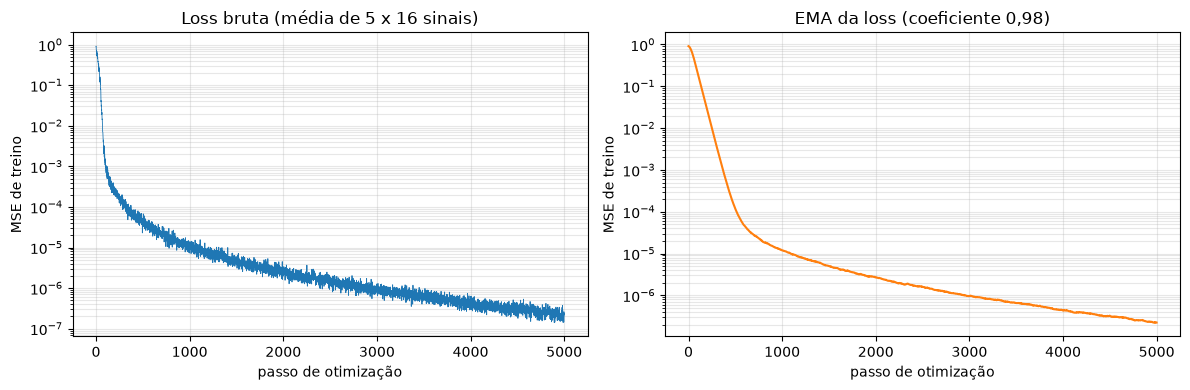

s final = 67.11


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 4.5: loss bruta à esquerda, EMA à direita, ambas em escala log
axes[0].plot(raw_loss_history, linewidth=0.6)
axes[0].set_title("Loss bruta (média de 5 x 16 sinais)")
axes[1].plot(smooth_loss_history, color="tab:orange")
axes[1].set_title("EMA da loss (coeficiente 0,98)")
for ax in axes:
    ax.set_yscale("log")
    ax.set_xlabel("passo de otimização")
    ax.set_ylabel("MSE de treino")
    ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()
print(f"s final = {logit_scale.exp().item():.2f}")

### Resposta escrita 4

**Pergunta.** Por que fazer a média de várias sequências aleatórias reduz a variância da estimativa da loss sem
supervisionar diretamente a matriz de atenção?

**Resposta**

Para uma $A$ fixa, a MSE de um único sinal é uma variável aleatória: depende do $x$ sorteado. A média de $N$ sinais
independentes tem o mesmo valor esperado, mas variância $N$ vezes menor (desvio-padrão $\sqrt N$ vezes menor). Aqui a
loss de cada passo é a média de $5\times16=80$ MSEs, então ela oscila pouco de um passo para outro. O mesmo vale para o
gradiente, porque o gradiente da média é a média dos gradientes de cada sinal. O otimizador recebe uma direção menos
ruidosa.

Isso não supervisiona a atenção diretamente: $R_L$ nunca é construída nem aparece no código da loss, que compara só
$\hat y=Ax$ com $y=\operatorname{flip}(x)$. A identidade do enunciado mostra por que funciona assim mesmo: em média, a
MSE de saída é $\frac1L\lVert A-R_L\rVert_F^2$, então ela só fica pequena quando $A$ se aproxima da matriz de inversão.
A informação sobre $A$ chega apenas pelos sinais sorteados. Um único $x$ fixo, usado em todos os passos, não bastaria:
$Ax=R_Lx$ são só $L$ equações para $L^2$ entradas de $A$, e muitas matrizes erradas as satisfariam.

## 5. Interpolação e extrapolação — 0,80 ponto

Avaliação em `L = 4, 5, 8, 12`. O modelo só foi treinado com comprimentos de 4 a 8. A acurácia de alinhamento
(o argmax da linha $i$ aponta para $L-1-i$) é só diagnóstico. A tabela inclui também o peso médio que $A$ coloca na
posição correta.

In [7]:
@torch.no_grad()
def evaluate_length(L, n_sequences=256):
    # 5.1: A para este comprimento
    positions = positional_features(L)
    A = compute_attention_weights(
        positions @ W_Q, positions @ W_K, logit_scale=logit_scale.exp()
    )

    # 5.2: MSE média em sinais novos
    mses = []
    for _ in range(n_sequences):
        x = torch.randn(L, 1)
        mses.append(F.mse_loss(A @ x, torch.flip(x, dims=[0])))
    test_mse = torch.stack(mses).mean().item()

    # 5.3: alinhamento pós-treino
    expected = torch.arange(L - 1, -1, -1)
    alignment_accuracy = (A.argmax(dim=-1) == expected).float().mean().item()
    correct_weight = A[torch.arange(L), expected].mean().item()

    return {
        "L": L,
        "test_mse": test_mse,
        "alignment_accuracy": alignment_accuracy,
        "correct_weight": correct_weight,
        "attention": A,
    }


results = [evaluate_length(L) for L in [4, 5, 8, 12]]

print(
    f"{'L':>3} | {'MSE de teste':>12} | {'alinhamento':>11} | {'peso correto':>12} | {'regime':<14}"
)
print("-" * 64)
for result in results:
    regime = "interpolação" if 4 <= result["L"] <= 8 else "extrapolação"
    print(
        f"{result['L']:>3} | "
        f"{result['test_mse']:>12.3e} | "
        f"{result['alignment_accuracy']:>10.1%} | "
        f"{result['correct_weight']:>12.3f} | {regime:<14}"
    )

  L | MSE de teste | alinhamento | peso correto | regime        
----------------------------------------------------------------
  4 |    0.000e+00 |     100.0% |        1.000 | interpolação  
  5 |    1.800e-22 |     100.0% |        1.000 | interpolação  
  8 |    1.134e-06 |     100.0% |        0.999 | interpolação  
 12 |    9.440e-03 |     100.0% |        0.927 | extrapolação  


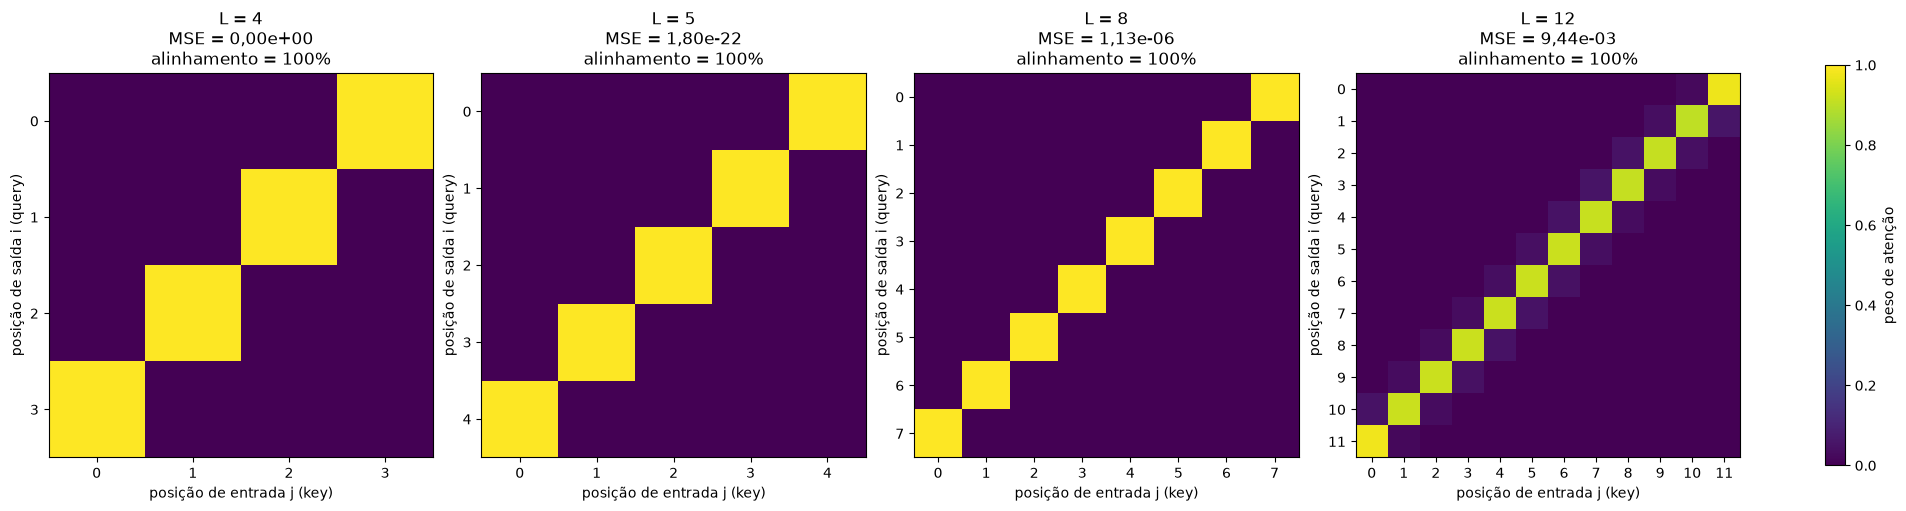

In [8]:
# 5.4: as quatro matrizes avaliadas (o enunciado pede heatmap para cada L), mesma escala de cor
lengths_to_plot = [4, 5, 8, 12]
fig, axes = plt.subplots(1, 4, figsize=(19, 5.2), constrained_layout=True)

by_length = {r["L"]: r for r in results}
for ax, L in zip(axes, lengths_to_plot):
    r = by_length[L]
    im = ax.imshow(r["attention"].numpy(), vmin=0, vmax=1, cmap="viridis")
    ax.set_title(
        f"L = {L}\nMSE = {r['test_mse']:.2e}\nalinhamento = {r['alignment_accuracy']:.0%}".replace(
            ".", ","
        )
    )
    ax.set_xlabel("posição de entrada j (key)")
    ax.set_ylabel("posição de saída i (query)")
    ax.set_xticks(range(L))
    ax.set_yticks(range(L))

fig.colorbar(im, ax=axes, shrink=0.8, label="peso de atenção")
plt.show()

## 6. Análise — 0,40 ponto

### Resposta escrita 6

**Perguntas**

1. Por que `L=8` é interpolação e `L=12` é extrapolação?
2. Posições normalizadas consecutivas ficam separadas por $2/(L-1)$. O que acontece quando `L` cresce?
3. Por que a acurácia de alinhamento pode continuar alta enquanto a MSE de regressão piora?
4. Uma escala de logits aprendível garante generalização para sequências arbitrariamente longas?
5. Compare os papéis de $Q$, $K$ e $V$ neste experimento.

**Respostas**

1. **Interpolação e extrapolação.** O treino cobre $L$ de 4 a 8. $L=8$ está dentro dessa faixa: é um dos
   comprimentos de treino, e seu espaçamento (0,286) é um dos que o modelo viu. $L=12$ está fora. As coordenadas
   continuam em $[-1,1]$, então não é extrapolação no intervalo de posições, e sim na **densidade**: o espaçamento de
   $2/11=0{,}182$ é menor que o menor espaçamento visto no treino. Como todos os comprimentos de 4 a 8 foram treinados,
   "interpolação" aqui quer dizer "dentro da distribuição de treino". A diferença aparece nos números: MSE de
   $1{,}1\times10^{-6}$ em $L=8$ contra $9{,}4\times10^{-3}$ em $L=12$, quase quatro ordens de grandeza a mais, embora o
   alinhamento continue em 100%.

2. **Os vizinhos da posição certa ficam mais perto e passam a receber peso.** $W_Q$, $W_K$ e $s$ são os mesmos para
   qualquer $L$, então a "largura" da atenção, medida na coordenada $p$, é fixa: o quanto o peso cai quando a key se
   afasta de $-p_i$ não depende de $L$. Quando $L$ cresce, o espaçamento $2/(L-1)$ encolhe, e os vizinhos da posição
   certa ficam mais próximos de $-p_i$. A tabela da seção 5 mostra isso. O peso médio na posição correta é 1,000 em
   $L=4$ e 5, 0,999 em $L=8$ (espaçamento 0,286) e cai para 0,927 em $L=12$ (espaçamento 0,182). Se $L$ continuar
   crescendo, a atenção acaba virando uma média de vários vizinhos.

3. **Argmax e MSE medem coisas diferentes.** O argmax só exige que a key certa tenha o **maior** peso. Em $L=12$ o
   peso certo ainda é, em média, 0,927, e o alinhamento de 100% mostra que ele continua sendo o maior em todas as
   linhas. A MSE mede **toda** a massa fora do lugar: os cerca de 7% que vazam para os vizinhos misturam
   outros valores da sequência em cada saída, e isso basta para levar a MSE de $10^{-6}$ para a ordem de $10^{-2}$ sem
   mudar nenhum argmax. O alinhamento é um critério de limiar; a MSE é contínua.

4. **Não.** O treino ajusta a nitidez da atenção só para os comprimentos de 4 a 8, e nada na loss fala de $L>8$. A
   nitidez não depende só de $s$: depende também do tamanho de $W_Q$ e $W_K$, e o treino ajusta a combinação. Depois do
   treino, os parâmetros ficam fixos, então a largura da atenção também fica fixa, enquanto o espaçamento $2/(L-1)$
   continua caindo. Para $L$ grande o bastante, os vizinhos recebem quase tanto peso quanto a posição certa, e a
   inversão se perde. A escala aprendível só ajusta a nitidez para os comprimentos vistos no treino; para servir a
   qualquer $L$, a atenção teria de ficar mais estreita à medida que $L$ cresce.

5. **Papéis de Q, K e V.**
   - $Q=P_LW_Q$ codifica **onde a posição de saída quer ler**.
   - $K=P_LW_K$ codifica **o endereço de cada posição de entrada**.
   - O produto dos dois define o roteamento $A$, que depende só de posições.
   - $V=x$ é o **conteúdo** transportado, sem transformação.

   Como $Q$ e $K$ não veem $x$, a mesma $A$ serve para todos os sinais de um comprimento, e por isso ela pode ser
   reaproveitada pelos 16 sinais de cada passo. Pela mesma razão, ela pode servir para qualquer outro tipo de valor:
   a extensão da Parte IV testa isso com vetores one-hot. É diferente da Parte I, em que $Q$, $K$ e $V$ vinham todos
   do mesmo $X$ e o roteamento dependia do conteúdo.

### Parâmetros salvos para a Parte IV

A extensão opcional da Parte IV reaproveita a atenção treinada aqui. Se o arquivo não existir, o notebook 4 refaz
este treino com a mesma seed.

In [9]:
torch.save(
    {
        "W_Q": W_Q.detach().clone(),
        "W_K": W_K.detach().clone(),
        "logit_scale": logit_scale.detach().clone(),
    },
    "part3_params.pt",
)
print("parâmetros salvos em part3_params.pt")

parâmetros salvos em part3_params.pt


## Fontes e uso de IA

- Slides da disciplina: *Transformers 2 — Attention Mechanism*, *Transformers 3 — Multi-head* e *Transformers 4 — Transformer* (Prof. Eric A. Antonelo).
- A. Zhang, Z. C. Lipton, M. Li e A. J. Smola, *Dive into Deep Learning*, cap. 11 (Attention Mechanisms and Transformers), d2l.ai.
- Documentação do PyTorch (`torch.softmax`, `Tensor.masked_fill`, `torch.nn.functional.mse_loss`, `torch.optim.Adam`, `torch.save`).
- Assistência de IA: Claude Code (Anthropic), usado na implementação. Executei e conferi todos os resultados.

## Checklist final

- [x] A dimensão das features de posição é sempre 3.
- [x] O treino inclui todos os comprimentos de 4 a 8 em cada passo.
- [x] A loss usa só as sequências previstas e as sequências alvo.
- [x] Os resultados incluem MSE, acurácia de alinhamento e heatmaps.
- [x] A diferença entre interpolação e extrapolação é discutida.